# Stage 4.1: Evaluation harness (v2)

Run top to bottom (Restart & Run All). Cell order matters.

## 1. Load the panel and build past-only baseline features

In [7]:
import pandas as pd, numpy as np
import xgboost as xgb

panel = (pd.read_parquet("../data/panel.parquet")
         .sort_values(["StockCode", "Week"]).reset_index(drop=True))
g = panel.groupby("StockCode")

# Baseline helpers (every value only looks at earlier rows)
panel["last_units"]  = g["units"].shift(1)
panel["roll4_units"] = g["units"].transform(lambda s: s.shift(1).rolling(4, min_periods=1).mean())

# Features used by the old XGBoost (v1)
panel["lag1_log_units"]  = g["log_units"].shift(1)
panel["roll4_log_units"] = g["log_units"].transform(lambda s: s.shift(1).rolling(4, min_periods=1).mean())
panel["lag1_log_price"]  = g["log_price"].shift(1)
panel["price_change"]    = panel["log_price"] - panel["lag1_log_price"]
panel["weeks_gap"]       = g["Week"].diff().dt.days / 7
panel["cat_code"]        = panel["category"].astype("category").cat.codes

# Same product, same week, one year earlier
ly = panel[["StockCode", "Week", "units"]].copy()
ly["Week"] = ly["Week"] + pd.Timedelta(weeks=52)
panel = panel.merge(ly.rename(columns={"units": "ly_units"}), on=["StockCode", "Week"], how="left")
print(panel.shape, panel["ly_units"].notna().mean().round(3))

(66694, 28) 0.203


## 2. Rolling-median feature (must run before the evaluation loop)

In [8]:
# Rolling-median baseline feature (median-type counterpart of the trailing mean)
# Must run BEFORE the evaluation loop, because split() slices from `panel`
panel["roll4_med_units"] = panel.groupby("StockCode")["units"].transform(
    lambda s: s.shift(1).rolling(4, min_periods=1).median())

## 3. Three expanding-window folds

In [9]:
FOLDS = [("F1", "2011-01-01", "2011-05-01"),
         ("F2", "2011-05-01", "2011-09-01"),
         ("F3", "2011-09-01", "2011-12-31")]   # F3 contains the Q4 peak

def split(fold):
    _, start, end = fold
    tr = panel[panel["Week"] < start]
    te = panel[(panel["Week"] >= start) & (panel["Week"] < end)]
    return tr, te

for f in FOLDS:
    tr, te = split(f)
    print(f[0], "train", len(tr), "test", len(te))

F1 train 36144 test 11072
F2 train 47216 test 11471
F3 train 58687 test 8007


## 4. Scoring at three grains

In [10]:
def wape(a, p): return np.abs(a - p).sum() / a.sum()

def score(te, pred, hv_products):
    d = te[["StockCode", "Week", "category", "units"]].copy()
    d["pred"] = pred
    d["month_start"] = d["Week"].dt.to_period("M").dt.to_timestamp()

    cw = d.groupby(["category", "Week"])[["units", "pred"]].sum()
    pm = d.groupby(["StockCode", "month_start"])[["units", "pred"]].sum()
    hv = d[d["StockCode"].isin(hv_products)]

    return {"PW WAPE": wape(d.units, d.pred),              # product-week (hardest)
            "CW WAPE": wape(cw.units, cw.pred),            # category-week
            "PM WAPE": wape(pm.units, pm.pred),            # product-month
            "PW WAPE (high-vol)": wape(hv.units, hv.pred), # products averaging 10+ units/week in training
            "Bias": d.pred.sum() / d.units.sum() - 1}      # negative = under-forecasting

## 5. Models to compare

In [11]:
def fallback(tr, te):
    pm = te["StockCode"].map(tr.groupby("StockCode")["units"].mean())
    return pm.fillna(tr["units"].mean())

def m_prod_mean(tr, te): return fallback(tr, te).values
def m_last(tr, te):      return te["last_units"].fillna(fallback(tr, te)).values
def m_roll4(tr, te):     return te["roll4_units"].fillna(fallback(tr, te)).values
def m_seasonal(tr, te):  return te["ly_units"].fillna(te["roll4_units"]).fillna(fallback(tr, te)).values

V1 = ["log_price", "price_change", "lag1_log_units", "roll4_log_units",
      "weeks_gap", "week_of_year", "month", "is_q4", "cat_code"]

def m_xgb_v1(tr, te):
    d = tr.dropna(subset=["lag1_log_units"])
    m = xgb.XGBRegressor(n_estimators=400, learning_rate=0.05, max_depth=5,
                         subsample=0.8, colsample_bytree=0.8, random_state=42)
    m.fit(d[V1], d["log_units"])
    return np.exp(m.predict(te[V1]))      # back to units; XGBoost handles NaN lags natively

models = {"Last week": m_last, "Trailing 4-wk mean": m_roll4, "Product mean (train)": m_prod_mean,
          "Same week last year": m_seasonal, "XGBoost v1": m_xgb_v1}

## 6. Diagnostic models (run after the models cell)

In [12]:
# Diagnostic models. Must run AFTER the models cell above (needs fallback, V1, models).
# If you re-run the models cell, re-run this cell too.

def m_roll4_median(tr, te):
    return te["roll4_med_units"].fillna(fallback(tr, te)).values

# XGBoost v1 with a bias correction learned on the last 15% of the training weeks
def m_xgb_v1_cal(tr, te):
    d = tr.dropna(subset=["lag1_log_units"])
    weeks = np.sort(d["Week"].unique())
    cut = weeks[int(len(weeks) * 0.85)]
    early, late = d[d["Week"] < cut], d[d["Week"] >= cut]
    m = xgb.XGBRegressor(n_estimators=400, learning_rate=0.05, max_depth=5,
                         subsample=0.8, colsample_bytree=0.8, random_state=42)
    m.fit(early[V1], early["log_units"])
    scale = late["units"].sum() / np.exp(m.predict(late[V1])).sum()
    return np.exp(m.predict(te[V1])) * scale

models["Trailing 4-wk median"] = m_roll4_median
models["XGBoost v1 (bias-corrected)"] = m_xgb_v1_cal

## 7. Run everything

In [13]:
print(len(models), "models:", list(models))
assert len(models) == 7, "Expected 7 models - re-run the models cell, then the diagnostic-models cell"

rows = []
for name, fn in models.items():
    for f in FOLDS:
        tr, te = split(f)
        hv = set(tr.groupby("StockCode")["units"].mean().loc[lambda s: s >= 10].index)
        r = score(te, fn(tr, te), hv)
        r.update(model=name, fold=f[0])
        rows.append(r)

res = pd.DataFrame(rows)
cols = ["PW WAPE", "CW WAPE", "PM WAPE", "PW WAPE (high-vol)", "Bias"]

print("\nAverage across folds (sorted by product-month WAPE)")
print(res.groupby("model")[cols].mean().round(3).sort_values("PM WAPE"))

print("\nProduct-week WAPE by fold")
print(res.pivot(index="model", columns="fold", values="PW WAPE").round(3))

print("\nProduct-month WAPE by fold")
print(res.pivot(index="model", columns="fold", values="PM WAPE").round(3))

print("\nBias by fold")
print(res.pivot(index="model", columns="fold", values="Bias").round(3))

7 models: ['Last week', 'Trailing 4-wk mean', 'Product mean (train)', 'Same week last year', 'XGBoost v1', 'Trailing 4-wk median', 'XGBoost v1 (bias-corrected)']

Average across folds (sorted by product-month WAPE)
                             PW WAPE  CW WAPE  PM WAPE  PW WAPE (high-vol)  \
model                                                                        
Last week                      0.977    0.300    0.455               0.975   
XGBoost v1                     0.689    0.364    0.525               0.683   
XGBoost v1 (bias-corrected)    0.766    0.257    0.541               0.748   
Trailing 4-wk median           0.811    0.312    0.590               0.814   
Trailing 4-wk mean             0.882    0.272    0.613               0.885   
Same week last year            0.993    0.310    0.729               1.013   
Product mean (train)           0.951    0.331    0.808               0.982   

                              Bias  
model                               
Last wee

In [14]:
g = panel.groupby("StockCode")   # fresh groupby: the old `g` points at the pre-merge panel

# 1. Price relative to the product's own recent price (negative = discounted vs. usual)
panel["ref_logp8"] = g["log_price"].transform(lambda s: s.shift(1).rolling(8, min_periods=2).mean())
panel["rel_price"] = panel["log_price"] - panel["ref_logp8"]

# 2. Weeks since the last price change
chg_date = panel["Week"].where(panel["price_change"].abs() > 0.01)
panel["weeks_since_chg"] = (panel["Week"] - chg_date.groupby(panel["StockCode"]).ffill()).dt.days / 7

# 3. Order-size signals (lagged only: current-week lines would leak the outcome)
panel["log_upl"]   = np.log(panel["units"] / panel["n_lines"])
panel["log_lines"] = np.log(panel["n_lines"])
g = panel.groupby("StockCode")
panel["lag1_log_upl"]   = g["log_upl"].shift(1)
panel["roll4_log_upl"]  = g["log_upl"].transform(lambda s: s.shift(1).rolling(4, min_periods=1).mean())
panel["lag1_log_lines"] = g["log_lines"].shift(1)

# 4. Longer history and volatility
panel["roll8_log_units"] = g["log_units"].transform(lambda s: s.shift(1).rolling(8, min_periods=2).mean())
panel["std4_log_units"]  = g["log_units"].transform(lambda s: s.shift(1).rolling(4, min_periods=2).std())
panel["max8_log_units"]  = g["log_units"].transform(lambda s: s.shift(1).rolling(8, min_periods=1).max())
panel["obs_so_far"]      = g.cumcount()

# 5. Substitute pricing: how discounted is the rest of the category this week?
panel["cat_rel_price"]  = panel.groupby(["category", "Week"])["rel_price"].transform("mean")
panel["own_vs_cat_rel"] = panel["rel_price"] - panel["cat_rel_price"]

# 6. Calendar
xmas = pd.to_datetime(panel["Week"].dt.year.astype(str) + "-12-25")
panel["weeks_to_xmas"] = ((xmas - panel["Week"]).dt.days / 7).clip(-10, 52)

print(panel[["rel_price", "weeks_since_chg", "lag1_log_upl", "own_vs_cat_rel"]].describe().round(2))

       rel_price  weeks_since_chg  lag1_log_upl  own_vs_cat_rel
count   63294.00         57556.00      64994.00        63294.00
mean       -0.02             7.90          1.20           -0.00
std         0.33            11.53          1.09            0.32
min        -2.34             0.00          0.00           -2.02
25%        -0.17             0.00          0.00           -0.14
50%         0.00             3.00          1.10           -0.01
75%         0.02            11.00          1.90            0.10
max         2.15            96.00          6.21            2.09


In [15]:
V2 = ["rel_price", "price_change", "weeks_since_chg", "own_vs_cat_rel", "cat_rel_price",
      "lag1_log_units", "roll4_log_units", "roll8_log_units", "std4_log_units", "max8_log_units",
      "lag1_log_upl", "roll4_log_upl", "lag1_log_lines",
      "weeks_gap", "obs_so_far", "week_of_year", "month", "is_q4", "weeks_to_xmas", "cat_code"]
# Note: absolute log_price is deliberately left out so price level can't act as a product ID

def make_xgb_log_cal(features):
    def fn(tr, te):
        d = tr.dropna(subset=["lag1_log_units"])
        weeks = np.sort(d["Week"].unique())
        cut = weeks[int(len(weeks) * 0.85)]
        early, late = d[d["Week"] < cut], d[d["Week"] >= cut]
        m = xgb.XGBRegressor(n_estimators=400, learning_rate=0.05, max_depth=5,
                             subsample=0.8, colsample_bytree=0.8, random_state=42)
        m.fit(early[features], early["log_units"])
        scale = late["units"].sum() / np.exp(m.predict(late[features])).sum()
        return np.exp(m.predict(te[features])) * scale
    return fn

new_models = {"XGBoost v2 (log, cal)": make_xgb_log_cal(V2)}

rows = []
for name, fn in new_models.items():
    for f in FOLDS:
        tr, te = split(f)
        hv = set(tr.groupby("StockCode")["units"].mean().loc[lambda s: s >= 10].index)
        r = score(te, fn(tr, te), hv)
        r.update(model=name, fold=f[0])
        rows.append(r)

res = pd.concat([res, pd.DataFrame(rows)], ignore_index=True)

keep = ["XGBoost v2 (log, cal)", "XGBoost v1 (bias-corrected)", "Trailing 4-wk mean", "Last week"]
view = res[res["model"].isin(keep)]
print(view.groupby("model")[["PW WAPE", "CW WAPE", "Bias"]].mean().round(3).sort_values("CW WAPE"))
print()
print(view.pivot(index="model", columns="fold", values="Bias").round(3))

                             PW WAPE  CW WAPE   Bias
model                                               
XGBoost v2 (log, cal)          0.774    0.240  0.046
XGBoost v1 (bias-corrected)    0.766    0.257  0.017
Trailing 4-wk mean             0.882    0.272 -0.015
Last week                      0.977    0.300 -0.022

fold                            F1     F2     F3
model                                           
Last week                    0.007 -0.029 -0.043
Trailing 4-wk mean           0.060 -0.049 -0.056
XGBoost v1 (bias-corrected) -0.022 -0.034  0.108
XGBoost v2 (log, cal)        0.043  0.113 -0.017


In [16]:
def make_xgb_count(features, objective="count:poisson", power=None):
    def fn(tr, te):
        d = tr.dropna(subset=["lag1_log_units"])
        weeks = np.sort(d["Week"].unique())
        cut = weeks[int(len(weeks) * 0.85)]
        early, late = d[d["Week"] < cut], d[d["Week"] >= cut]

        params = dict(objective=objective, learning_rate=0.03, max_depth=5,
                      subsample=0.8, colsample_bytree=0.8, min_child_weight=5,
                      random_state=42)
        if power is not None:
            params["tweedie_variance_power"] = power

        # 1) find the number of trees using the most recent training weeks as validation
        m = xgb.XGBRegressor(n_estimators=2000, early_stopping_rounds=50, **params)
        m.fit(early[features], early["units"],
              eval_set=[(late[features], late["units"])], verbose=False)

        # 2) refit on all training data with that tree count (uses the most recent weeks too)
        m2 = xgb.XGBRegressor(n_estimators=m.best_iteration + 1, **params)
        m2.fit(d[features], d["units"])
        return m2.predict(te[features])
    return fn

new_models = {
    "XGB Poisson (v1 feats)":      make_xgb_count(V1, "count:poisson"),
    "XGB Poisson (v2 feats)":      make_xgb_count(V2, "count:poisson"),
    "XGB Tweedie 1.5 (v2 feats)":  make_xgb_count(V2, "reg:tweedie", power=1.5),
}

rows = []
for name, fn in new_models.items():
    for f in FOLDS:
        tr, te = split(f)
        hv = set(tr.groupby("StockCode")["units"].mean().loc[lambda s: s >= 10].index)
        r = score(te, fn(tr, te), hv)
        r.update(model=name, fold=f[0])
        rows.append(r)

res = res[~res["model"].isin(new_models)]          # safe to re-run: removes old copies first
res = pd.concat([res, pd.DataFrame(rows)], ignore_index=True)

keep = list(new_models) + ["XGBoost v2 (log, cal)", "XGBoost v1 (bias-corrected)", "Trailing 4-wk mean"]
view = res[res["model"].isin(keep)]
print(view.groupby("model")[["PW WAPE", "CW WAPE", "Bias"]].mean().round(3).sort_values("CW WAPE"))
print("\nBias by fold")
print(view.pivot(index="model", columns="fold", values="Bias").round(3))
print("\nPW WAPE by fold")
print(view.pivot(index="model", columns="fold", values="PW WAPE").round(3))

                             PW WAPE  CW WAPE   Bias
model                                               
XGB Tweedie 1.5 (v2 feats)     0.750    0.229  0.023
XGBoost v2 (log, cal)          0.774    0.240  0.046
XGB Poisson (v2 feats)         0.772    0.246  0.082
XGBoost v1 (bias-corrected)    0.766    0.257  0.017
Trailing 4-wk mean             0.882    0.272 -0.015
XGB Poisson (v1 feats)         0.791    0.276  0.100

Bias by fold
fold                            F1     F2     F3
model                                           
Trailing 4-wk mean           0.060 -0.049 -0.056
XGB Poisson (v1 feats)       0.129  0.054  0.118
XGB Poisson (v2 feats)       0.130  0.071  0.046
XGB Tweedie 1.5 (v2 feats)   0.068  0.008 -0.007
XGBoost v1 (bias-corrected) -0.022 -0.034  0.108
XGBoost v2 (log, cal)        0.043  0.113 -0.017

PW WAPE by fold
fold                            F1     F2     F3
model                                           
Trailing 4-wk mean           0.966  0.857  0.822
XGB Po

In [17]:
def fit_count_model(d, features, power=1.5, mono=None):
    params = dict(objective="reg:tweedie", tweedie_variance_power=power, learning_rate=0.03,
                  max_depth=5, subsample=0.8, colsample_bytree=0.8, min_child_weight=5,
                  random_state=42)
    if mono:
        params["monotone_constraints"] = "(" + ",".join(str(mono.get(f, 0)) for f in features) + ")"
    weeks = np.sort(d["Week"].unique())
    cut = weeks[int(len(weeks) * 0.85)]
    early, late = d[d["Week"] < cut], d[d["Week"] >= cut]
    m = xgb.XGBRegressor(n_estimators=2000, early_stopping_rounds=50, **params)
    m.fit(early[features], early["units"], eval_set=[(late[features], late["units"])], verbose=False)
    m2 = xgb.XGBRegressor(n_estimators=m.best_iteration + 1, **params)
    m2.fit(d[features], d["units"])
    return m2

MONO = {"rel_price": -1, "price_change": -1, "own_vs_cat_rel": -1}   # demand can't rise when own price rises

tr, te = split(FOLDS[2])                      # Fold 3 (train before 2011-09-01, test Sep-Dec 2011)
d = tr.dropna(subset=["lag1_log_units"])
hv = set(tr.groupby("StockCode")["units"].mean().loc[lambda s: s >= 10].index)

free = fit_count_model(d, V2)
mono = fit_count_model(d, V2, mono=MONO)

# 1) Does the constraint cost accuracy?
for name, m in [("Tweedie free", free), ("Tweedie monotone", mono)]:
    r = score(te, m.predict(te[V2]), hv)
    print(f"{name:<18} PW {r['PW WAPE']:.3f}  CW {r['CW WAPE']:.3f}  Bias {r['Bias']:+.3f}")

# 2) Price-shift simulation: raise/cut every product's own price in the test set
def simulate(model, delta):
    t = te.copy()
    s = np.log(1 + delta)
    for c in ["rel_price", "price_change", "own_vs_cat_rel"]:
        t[c] = t[c] + s
    return model.predict(t[V2])

print()
for name, m in [("free", free), ("monotone", mono)]:
    base = m.predict(te[V2])
    for dlt in [-0.10, -0.05, 0.05, 0.10]:
        lr = np.log(simulate(m, dlt) / base)
        print(f"{name:<9} price {dlt:+.0%}: implied elasticity {lr.mean() / np.log(1 + dlt):.2f}")

# 3) By category for the monotone model (price -10%)
cats = te.assign(lr=np.log(simulate(mono, -0.10) / mono.predict(te[V2])))
print()
print((cats.groupby("category")["lr"].mean() / np.log(0.90)).round(2).sort_values())

Tweedie free       PW 0.747  CW 0.252  Bias -0.007
Tweedie monotone   PW 0.757  CW 0.251  Bias -0.002

free      price -10%: implied elasticity -4.79
free      price -5%: implied elasticity -7.09
free      price +5%: implied elasticity -2.83
free      price +10%: implied elasticity -2.12
monotone  price -10%: implied elasticity -3.34
monotone  price -5%: implied elasticity -5.21
monotone  price +5%: implied elasticity -3.66
monotone  price +10%: implied elasticity -2.61

category
Toys & Kids               -3.59
Lighting & Candles        -3.53
Jewellery & Accessories   -3.53
Paper & Party             -3.46
Bags & Storage            -3.37
Other                     -3.34
Garden & Outdoor          -3.32
Kitchen & Dining          -3.27
Home Decor                -3.25
Christmas & Seasonal      -3.13
Stationery                -3.12
Name: lr, dtype: float32


In [18]:
import statsmodels.api as sm

# Controls: only information known BEFORE this week's price (no price-derived features from week t)
panel["mkt_lag1"] = panel.groupby("Week")["lag1_log_units"].transform("mean")                    # market momentum
panel["cat_lag1"] = panel.groupby(["category", "Week"])["lag1_log_units"].transform("mean")      # category momentum

XD = ["ref_logp8", "lag1_log_units", "roll4_log_units", "roll8_log_units", "std4_log_units",
      "max8_log_units", "lag1_log_upl", "roll4_log_upl", "lag1_log_lines", "weeks_gap",
      "obs_so_far", "week_of_year", "month", "is_q4", "weeks_to_xmas", "cat_code",
      "mkt_lag1", "cat_lag1"]

dml = panel.dropna(subset=["rel_price", "log_units"]).copy()
weeks = np.sort(dml["Week"].unique())
K = 5
block_of = {w: i * K // len(weeks) for i, w in enumerate(weeks)}
dml["blk"] = dml["Week"].map(block_of)
print(dml.shape)

def cross_fit(target):
    pred = np.zeros(len(dml))
    for b in range(K):
        tr_i, te_i = (dml["blk"] != b).values, (dml["blk"] == b).values
        m = xgb.XGBRegressor(n_estimators=300, learning_rate=0.05, max_depth=5, subsample=0.8,
                             colsample_bytree=0.8, min_child_weight=10, random_state=42)
        m.fit(dml.loc[tr_i, XD], dml.loc[tr_i, target])
        pred[te_i] = m.predict(dml.loc[te_i, XD])
    return pred

y_res = dml["log_units"] - cross_fit("log_units")
t_res = dml["rel_price"] - cross_fit("rel_price")

print("Share of log_units explained by controls:", round(1 - y_res.var() / dml["log_units"].var(), 3))
print("Share of rel_price explained by controls:", round(1 - t_res.var() / dml["rel_price"].var(), 3))

groups = dml["StockCode"].astype("category").cat.codes
fit = sm.OLS(y_res, t_res).fit(cov_type="cluster", cov_kwds={"groups": groups})
th, se = fit.params.iloc[0], fit.bse.iloc[0]
print(f"\nDML elasticity: {th:.3f}  (SE {se:.3f}, 95% CI {th - 1.96*se:.3f} to {th + 1.96*se:.3f})")

rows = []
for cat in dml["category"].unique():
    mk = (dml["category"] == cat).values
    if dml.loc[mk, "StockCode"].nunique() < 20:
        continue
    f = sm.OLS(y_res[mk], t_res[mk]).fit(cov_type="cluster", cov_kwds={"groups": groups[mk]})
    rows.append((cat, f.params.iloc[0], f.bse.iloc[0], dml.loc[mk, "StockCode"].nunique()))
bycat = pd.DataFrame(rows, columns=["category", "elasticity", "se", "products"]).sort_values("elasticity")
bycat["ci_low"] = bycat["elasticity"] - 1.96 * bycat["se"]
bycat["ci_high"] = bycat["elasticity"] + 1.96 * bycat["se"]
print(bycat.round(3))

(63294, 47)
Share of log_units explained by controls: 0.269
Share of rel_price explained by controls: 0.006

DML elasticity: -1.688  (SE 0.020, 95% CI -1.727 to -1.649)
                   category  elasticity     se  products  ci_low  ci_high
1                Stationery      -2.166  0.122        67  -2.405   -1.926
2             Paper & Party      -1.965  0.094       138  -2.150   -1.780
9               Toys & Kids      -1.938  0.176        28  -2.283   -1.594
10     Christmas & Seasonal      -1.839  0.116        63  -2.066   -1.611
3          Garden & Outdoor      -1.788  0.076        99  -1.938   -1.638
7        Lighting & Candles      -1.719  0.052       168  -1.821   -1.617
0                     Other      -1.640  0.035       516  -1.709   -1.570
8                Home Decor      -1.619  0.050       216  -1.717   -1.520
5            Bags & Storage      -1.617  0.058       160  -1.731   -1.503
4          Kitchen & Dining      -1.548  0.053       178  -1.652   -1.444
6   Jewellery & A

                    n  price_dev  mean_y_res     se  price_pct  linear_fit
bin                                                                       
(-1.0, -0.4]     3807     -0.583       0.719  0.020      -44.2       0.985
(-0.4, -0.25]    5187     -0.308       0.386  0.015      -26.5       0.520
(-0.25, -0.15]   6674     -0.187       0.313  0.013      -17.1       0.316
(-0.15, -0.07]   9556     -0.096       0.166  0.011       -9.1       0.162
(-0.07, -0.02]   2135     -0.047      -0.075  0.020       -4.6       0.080
(-0.02, 0.02]   19668      0.001       0.041  0.007        0.1      -0.001
(0.02, 0.07]     2516      0.037      -0.142  0.019        3.7      -0.062
(0.07, 0.15]     1680      0.107      -0.266  0.023       11.3      -0.181
(0.15, 0.25]     1540      0.193      -0.483  0.022       21.3      -0.326
(0.25, 0.4]      2347      0.320      -0.739  0.017       37.7      -0.540
(0.4, 1.0]       6976      0.592      -1.193  0.010       80.8      -1.000


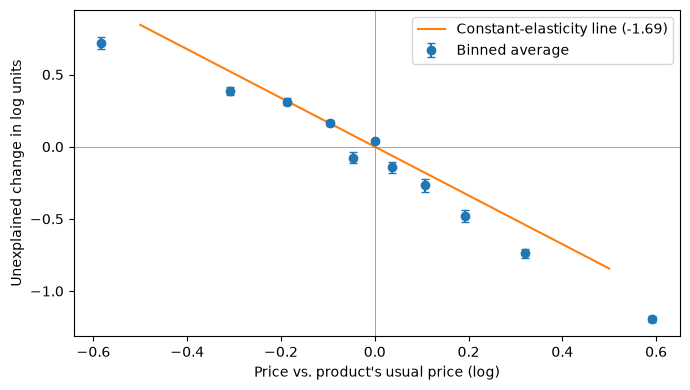

                   category  dml_elasticity  dml_se  products  dml_ci_low  \
0                Stationery          -2.166   0.122        67      -2.405   
1             Paper & Party          -1.965   0.094       138      -2.150   
2               Toys & Kids          -1.938   0.176        28      -2.283   
3      Christmas & Seasonal          -1.839   0.116        63      -2.066   
4          Garden & Outdoor          -1.788   0.076        99      -1.938   
5        Lighting & Candles          -1.719   0.052       168      -1.821   
6                     Other          -1.640   0.035       516      -1.709   
7                Home Decor          -1.619   0.050       216      -1.717   
8            Bags & Storage          -1.617   0.058       160      -1.731   
9          Kitchen & Dining          -1.548   0.053       178      -1.652   
10  Jewellery & Accessories          -1.307   0.121        67      -1.545   

    dml_ci_high  fe_elasticity  
0        -1.926         -1.987  
1        

In [19]:
import matplotlib.pyplot as plt

dml["y_res"] = y_res.values
dml["t_res"] = t_res.values

bins = [-1.0, -0.4, -0.25, -0.15, -0.07, -0.02, 0.02, 0.07, 0.15, 0.25, 0.4, 1.0]
dml["bin"] = pd.cut(dml["rel_price"], bins)
tab = dml.groupby("bin", observed=True).agg(
    n=("y_res", "size"),
    price_dev=("rel_price", "mean"),
    mean_y_res=("y_res", "mean"),
    se=("y_res", lambda s: s.std() / np.sqrt(len(s))))
tab["price_pct"] = ((np.exp(tab["price_dev"]) - 1) * 100).round(1)
tab["linear_fit"] = th * tab["price_dev"]
print(tab.round(3))

fig, ax = plt.subplots(figsize=(7, 4))
ax.errorbar(tab["price_dev"], tab["mean_y_res"], yerr=1.96 * tab["se"], fmt="o", capsize=3, label="Binned average")
xs = np.linspace(-0.5, 0.5, 50)
ax.plot(xs, th * xs, label=f"Constant-elasticity line ({th:.2f})")
ax.axhline(0, color="grey", lw=0.5); ax.axvline(0, color="grey", lw=0.5)
ax.set_xlabel("Price vs. product's usual price (log)")
ax.set_ylabel("Unexplained change in log units")
ax.legend(); plt.tight_layout()
plt.savefig("../docs/price_response_binned.png", dpi=150)
plt.show()

# Final elasticity table for Power BI (DML + FE side by side)
fe = (pd.read_csv("../data/elasticity_by_category.csv")[["category", "elasticity"]]
        .rename(columns={"elasticity": "fe_elasticity"}))
final = (bycat.rename(columns={"elasticity": "dml_elasticity", "se": "dml_se",
                               "ci_low": "dml_ci_low", "ci_high": "dml_ci_high"})
              .merge(fe, on="category", how="left"))
final.to_csv("../data/elasticity_final.csv", index=False)
print(final.round(3))

In [1]:
lo_cut, hi_hike = np.log(0.80), np.log(1.20)      # the simulator's +/-20% range, in logs

def slope(mask):
    m = mask.values
    X = sm.add_constant(dml.loc[m, "t_res"])
    f = sm.OLS(dml.loc[m, "y_res"], X).fit(cov_type="cluster", cov_kwds={"groups": groups[m]})
    return f.params["t_res"], f.bse["t_res"], int(m.sum())

th_cut,  se_cut,  n_cut  = slope((dml["rel_price"] >= lo_cut) & (dml["rel_price"] < 0))
th_hike, se_hike, n_hike = slope((dml["rel_price"] > 0) & (dml["rel_price"] <= hi_hike))

print(f"Cuts  (0% to -20%): slope {th_cut:.2f} (SE {se_cut:.2f}), n={n_cut}")
print(f"Hikes (0% to +20%): slope {th_hike:.2f} (SE {se_hike:.2f}), n={n_hike}")

k_cut, k_hike = th_cut / th, th_hike / th
print(f"k_cut = {k_cut:.2f}, k_hike = {k_hike:.2f}   (vs. overall DML {th:.2f})")

final["k_cut"], final["k_hike"] = round(k_cut, 3), round(k_hike, 3)
final.to_csv("../data/elasticity_final.csv", index=False)

NameError: name 'np' is not defined